<a href="https://colab.research.google.com/github/madhav8199/Capstone-project/blob/main/Thermal_Power_Budgeting.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Capstone Problem A: Thermal-Aware Power Budgeting on a Chip

**Course:** PDEs, Transforms & Optimization Techniques · **Batch:** S3 EC AY-2025-2026 · **Group 11**

**Team:** Mithu Antony · Madhav S · Alwin Binoj · Abhishek S · Krishna S

## Aim
To model the steady-state and transient temperature of a silicon die with four heat-dissipating blocks using a PDE, and to find the power allocation across the blocks that minimizes the peak chip temperature for a fixed total power budget, using a Linear Program.

### Objectives

*   To derive the heat-conduction model from Fourier's law and the energy balance (vector calculus).

*   To classify the resulting PDE and state well-posed boundary conditions.

*   To use the Laplace Transform in time to obtain the thermal impedance $Z_{th}(s)$.

*   To discretize the PDE with the 5-point finite-difference stencil into a sparse linear system.

*   To formulate and solve the min–max temperature problem as a Linear Program (epigraph form).

*   To verify the results with limiting cases and visualize the temperature fields.

 ### Algorithm: The Thermal Power-Budgeting Pipeline
The process follows a six-stage pipeline, each stage drawing on a different course:

| Stage | Topic | Course |
|---|---|---|
| 1 | Field model (grad, div) | Vector Calculus (Sem 2) |
| 2 | PDE classification + BCs | PDEs (Sem 3) |
| 3 | Laplace transform, $Z_{th}(s)$ | Transforms (Sem 3) |
| 4 | 5-point FDM, sparse system | Linear Algebra (Sem 1) |
| 5 | Linear program (min–max temperature) | Optimization / LP (Sem 3) |
| 6 | Verification + figures | Python Lab (Sem 3) |

1. **Model**: Write the heat equation from Fourier's law and the energy balance; the steady state is the 2-D Poisson equation.
2. **Transform & Discretize**: Apply the Laplace transform in time and the 5-point stencil in space, giving $\big(sC-A\big)\hat{\boldsymbol\theta}=\hat{\mathbf q}$.
3. **Optimize**: Choose block powers $\mathbf q$ by solving an LP that minimizes the peak temperature, then verify the answer numerically.

Run **Runtime → Run all**. Everything (all six stages and all figures) regenerates in a few seconds.

### Case Study: Four-Block Chip with Edge Heat Sink
**Problem**: A square silicon die of side $L=10$ mm ($k=150$ W/(m·K)) carries four heat-dissipating blocks at grid positions $(10,10),(10,29),(29,10),(29,29)$ on a $40\times40$ grid. The die edges are held at the ambient temperature $T_{amb}=300$ K by a heat sink. Distribute a total power budget $P_{max}=5$ W among the four blocks so that the peak temperature is as low as possible.

**Step-by-Step Solution:**

1. **Field model (Vector Calculus):**

   Let $\theta(x,y,t)=T-T_{amb}$ be the temperature rise in a die of thickness $d$.

   *   **Fourier's law:** $\mathbf q'' = -k\nabla T$ (heat flux, W/m²).
   *   **Energy balance** on a small control volume (divergence theorem): $$\rho c\,\frac{\partial T}{\partial t} = -\nabla\!\cdot\!\mathbf q'' + Q$$ where $Q$ (W/m³) is the volumetric heat generation of the blocks.
   *   Substituting Fourier's law: $\rho c\,T_t = \nabla\!\cdot(k\nabla T)+Q = k\nabla^2 T + Q$ (constant $k$).
   *   **Steady state** ($T_t=0$): $\boxed{\nabla^2 T = -Q/k}$ — the 2-D Poisson equation.

   A block dissipating $q_i$ watts at a point gives $Q = q_i\,\delta(\mathbf r-\mathbf r_i)/d$.

2. **PDE formulation and classification:**

   *   $k\left(\frac{\partial^2 T}{\partial x^2}+\frac{\partial^2 T}{\partial y^2}\right) = -Q,\qquad 0\le x,y\le L$
   *   **Classification:** for $A u_{xx}+Bu_{xy}+Cu_{yy}$ with $A=C=1,\ B=0$: $B^2-4AC=-4<0$ ⇒ **elliptic**.
   *   **Boundary conditions:** Dirichlet $T=T_{amb}=300$ K on all four edges (the heat sink holds the edge at ambient).
   *   **Well-posedness:** elliptic + Dirichlet ⇒ unique solution that depends continuously on $Q$ (maximum principle: the hottest point is inside, at a block).
   *   The *transient* form $\rho c\,T_t=k\nabla^2T+Q$ is **parabolic** and is used in the next step.

Let's set up the problem data in Python.

In [1]:
import numpy as np
import scipy.sparse as sp
import scipy.sparse.linalg as spla
from scipy.optimize import linprog
import sympy as sps
import matplotlib.pyplot as plt

# ---------------- problem data (from the brief) ----------------
L      = 10e-3        # die side [m]
k      = 150.0        # silicon conductivity [W/(m K)]
T_amb  = 300.0        # edge temperature [K]
P_max  = 5.0          # total power budget [W]
N      = 40           # grid is N x N nodes (boundary included)
h      = L/(N-1)      # grid spacing [m]
n      = N-2          # interior nodes per side
BLOCKS = [(10,10),(10,29),(29,10),(29,29)]   # (row, col) on the 40x40 grid

# Not given in the brief: die thickness (2-D -> 3-D conversion).
# 0.145 mm is chosen so that the uniform-power peak is ~343 K, as in the reference values.
d_die  = 0.145e-3     # [m]
rho, cp = 2329.0, 700.0   # silicon density [kg/m3], specific heat [J/(kg K)] (used in Stage 3 only)
print(f"h = {h*1e3:.4f} mm, interior grid = {n} x {n} = {n*n} unknowns")

h = 0.2564 mm, interior grid = 38 x 38 = 1444 unknowns


3. **Laplace transform in time and thermal impedance $Z_{th}(s)$:**

   Take the Laplace transform of $\rho c\,T_t = k\nabla^2T+Q$ with zero initial rise ($\theta(0)=0$), $\hat\theta(\mathbf r,s)=\mathcal L\{\theta\}$:
   $$\rho c\,s\,\hat\theta = k\nabla^2\hat\theta + \hat Q(s)\quad\Longrightarrow\quad (\rho c\,s - k\nabla^2)\,\hat\theta=\hat Q .$$
   The time derivative became multiplication by $s$, leaving an *elliptic* problem. On the grid (next step) this reads
   $$\big(sC - A\big)\hat{\boldsymbol\theta}(s)=\hat{\mathbf q}(s)\ \Rightarrow\ \hat{\boldsymbol\theta}(s)=Z_{th}(s)\,\hat{\mathbf q}(s),\qquad Z_{th}(s)=(sC-A)^{-1}$$
   with $C=\rho c\,d\,h^2$ the nodal heat capacity. **Single-mode (lumped RC) picture:** for an eigenmode with conductance $G$, $Z(s)=\dfrac{1}{Cs+G}$ — thermal resistance $1/G$ in parallel with capacitance $C$. The steady state is $s\to0$.

Let's verify the modal impedance, its step response and the final-value theorem with SymPy.

In [2]:
s_, t_ = sps.symbols('s t', positive=True)
C_, G_ = sps.symbols('C G', positive=True)

Z   = 1/(C_*s_ + G_)                       # modal thermal impedance Z_th(s)
Zdc = sps.limit(Z, s_, 0)                  # s -> 0  : steady-state thermal resistance
step_hat = Z/s_                            # response to a unit power step: P(s) = 1/s
try:
    step_t = sps.simplify(sps.inverse_laplace_transform(step_hat, s_, t_))
except Exception:
    step_t = (1 - sps.exp(-G_*t_/C_))/G_      # closed form by partial fractions
fvt = sps.limit(s_*step_hat, s_, 0)        # final-value theorem
tau = C_/G_                                # thermal time constant

print("Z_th(s)               =", Z)
print("Z_th(s -> 0)          =", Zdc, "   <- steady-state thermal resistance")
print("step response T(t)    =", step_t)
print("final value (s*Z/s)   =", fvt, "  (equals Z_th(0), as the theorem says)")
print("time constant tau     =", tau)

Z_th(s)               = 1/(C*s + G)
Z_th(s -> 0)          = 1/G    <- steady-state thermal resistance
step response T(t)    = 1/G - exp(-G*t/C)/G
final value (s*Z/s)   = 1/G   (equals Z_th(0), as the theorem says)
time constant tau     = C/G


4. **Discretization: 5-point finite differences → sparse linear system:**

   At an interior node $(i,j)$, with a block power $q_{ij}$ [W] injected at that node:
   $$k\,d\,\big(\theta_{i+1,j}+\theta_{i-1,j}+\theta_{i,j+1}+\theta_{i,j-1}-4\theta_{i,j}\big) = -q_{ij}$$
   (the $h^2$ cancels in 2-D). Edge nodes have $\theta=0$ (Dirichlet), so they drop out of the unknowns. This gives
   $$A\boldsymbol\theta = -\mathbf q,\qquad A = k\,d\,(I\otimes D + D\otimes I),\quad D=\mathrm{tridiag}(1,-2,1).$$
   $A$ is **symmetric negative definite** (all eigenvalues $<0$) ⇒ unique solution and a stable Poisson solve.

Let's build $A$ with `scipy.sparse` and check its definiteness.

In [3]:
def laplacian_2d(n):
    D = sp.diags([np.ones(n-1), -2*np.ones(n), np.ones(n-1)], [-1,0,1], format='csr')
    I = sp.identity(n, format='csr')
    return (sp.kron(I, D) + sp.kron(D, I)).tocsr()

A = (k*d_die*laplacian_2d(n)).tocsc()        # [W/K], negative definite

def node(i, j):                               # grid (row,col) -> interior vector index
    return (i-1)*n + (j-1)

blk_idx = [node(i, j) for (i, j) in BLOCKS]
E = sp.csr_matrix((np.ones(len(BLOCKS)), (blk_idx, range(len(BLOCKS)))), shape=(n*n, len(BLOCKS)))

lam_max = np.linalg.eigvalsh(A.toarray()).max()
print("A shape:", A.shape, "| nnz:", A.nnz, "| E shape:", E.shape)
print(f"max eigenvalue of A = {lam_max:.4e}  (negative -> stable)  ->", lam_max < 0)

def solve_T(q):
    # returns the full NxN temperature field [K] for block powers q [W]
    theta = spla.spsolve(A, -(E @ q))
    T = np.full((N, N), T_amb)
    T[1:-1, 1:-1] += theta.reshape(n, n)
    return T

A shape: (1444, 1444) | nnz: 7068 | E shape: (1444, 4)
max eigenvalue of A = -2.8211e-04  (negative -> stable)  -> True


5. **Linear program (min–max temperature):**

   Decision variables $x=[\,\mathbf q\ (4),\ \boldsymbol\theta\ (n^2),\ t\,]$. We minimise the **epigraph variable** $t$, which bounds every node temperature:
   $$\min_{\mathbf q,\boldsymbol\theta,t}\ t\quad\text{s.t.}\quad A\boldsymbol\theta + E\mathbf q = 0,\quad -t\le\theta_i\le t,\quad \sum_i q_i = P_{max},\quad \mathbf q\ge0 .$$
   Why it is linear: $\max_i|\theta_i|$ is non-linear, but the epigraph trick replaces it by $2n^2$ linear inequalities $\theta_i-t\le0,\ -\theta_i-t\le0$; the PDE enters as a linear equality.

> **Note:** the brief writes $\sum q_i\le P_{max}$. With "$\le$" the trivial answer is $\mathbf q=0,\ t=0$ (no power ⇒ no heating). We therefore use **equality** — the whole budget must be allocated.

Let's solve the LP with `scipy.optimize.linprog` (HiGHS).

In [4]:
def solve_lp(Pmax=P_max):
    nq, nt = len(BLOCKS), n*n
    nv = nq + nt + 1
    c = np.zeros(nv); c[-1] = 1.0                                   # minimise t
    # equality: A*theta + E*q = 0
    A_eq1 = sp.hstack([E, A, sp.csr_matrix((nt, 1))])
    # equality: sum(q) = Pmax
    A_eq2 = sp.csr_matrix(np.r_[np.ones(nq), np.zeros(nt), 0.0].reshape(1, -1))
    A_eq = sp.vstack([A_eq1, A_eq2]).tocsr()
    b_eq = np.r_[np.zeros(nt), Pmax]
    # inequalities:  theta - t <= 0   and   -theta - t <= 0
    Z0 = sp.csr_matrix((nt, nq)); onecol = sp.csr_matrix(np.ones((nt, 1)))
    A_ub = sp.vstack([sp.hstack([Z0,  sp.identity(nt), -onecol]),
                      sp.hstack([Z0, -sp.identity(nt), -onecol])]).tocsr()
    b_ub = np.zeros(2*nt)
    bounds = [(0, None)]*nq + [(None, None)]*nt + [(0, None)]
    res = linprog(c, A_ub=A_ub, b_ub=b_ub, A_eq=A_eq, b_eq=b_eq, bounds=bounds, method='highs')
    return res, res.x[:nq]

res, q_opt = solve_lp(P_max)
print("res.success =", res.success, "|", res.message)
print("optimal q [W] =", np.round(q_opt, 4), "| sum =", q_opt.sum())

res.success = True | Optimization terminated successfully. (HiGHS Status 7: Optimal)
optimal q [W] = [1.25 1.25 1.25 1.25] | sum = 5.0


6. **Python pipeline, figures and verification:**

   Compare the uniform allocation $q_i=P_{max}/4$ with the LP-optimal allocation: temperature fields, power allocation and the peak temperature as the budget $P_{max}$ varies.

Let's solve and visualize.

Uniform  peak = 343.28 K
LP-opt   peak = 343.28 K   (LP objective t + T_amb = 343.28 K)
Reduction     = -0.000 K


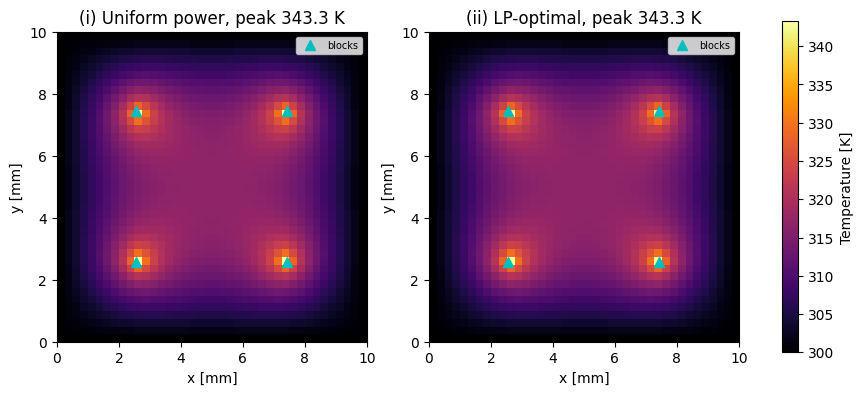

In [ ]:
q_uni = np.full(len(BLOCKS), P_max/len(BLOCKS))
T_uni = solve_T(q_uni)
T_lp  = solve_T(q_opt)
print(f"Uniform  peak = {T_uni.max():.2f} K")
print(f"LP-opt   peak = {T_lp.max():.2f} K   (LP objective t + T_amb = {T_amb+res.x[-1]:.2f} K)")
print(f"Reduction     = {T_uni.max()-T_lp.max():.3f} K")

def heatmap(ax, T, title, vmin, vmax):
    im = ax.imshow(T, origin='lower', extent=[0, L*1e3, 0, L*1e3], cmap='inferno', vmin=vmin, vmax=vmax)
    bx = [(j*h*1e3) for (_, j) in BLOCKS]; by = [(i*h*1e3) for (i, _) in BLOCKS]
    ax.plot(bx, by, 'c^', ms=7, label='blocks'); ax.set_title(title)
    ax.set_xlabel('x [mm]'); ax.set_ylabel('y [mm]'); ax.legend(loc='upper right', fontsize=7)
    return im

vmin, vmax = T_amb, max(T_uni.max(), T_lp.max())
fig, axs = plt.subplots(1, 2, figsize=(11, 4.3))
im = heatmap(axs[0], T_uni, f'(i) Uniform power, peak {T_uni.max():.1f} K', vmin, vmax)
heatmap(axs[1], T_lp, f'(ii) LP-optimal, peak {T_lp.max():.1f} K', vmin, vmax)
fig.colorbar(im, ax=axs, label='Temperature [K]'); plt.show()

In [5]:
# (iii) power-allocation bar chart
labels = [f'B{i+1}\n{b}' for i, b in enumerate(BLOCKS)]
x = np.arange(len(BLOCKS)); w = 0.38
plt.figure(figsize=(6.5, 3.8))
plt.bar(x-w/2, q_uni, w, label='Uniform'); plt.bar(x+w/2, q_opt, w, label='LP-optimal')
plt.xticks(x, labels); plt.ylabel('Block power [W]'); plt.xlabel('Block (grid position)')
plt.title('(iii) Power allocation'); plt.legend(); plt.tight_layout(); plt.show()

NameError: name 'q_uni' is not defined

<Figure size 650x380 with 0 Axes>

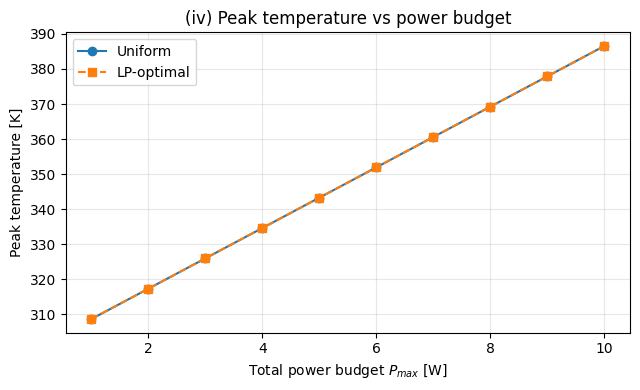

In [ ]:
# (iv) peak temperature vs P_max sweep
Ps = np.linspace(1, 10, 10)
pk_uni, pk_lp = [], []
for P in Ps:
    r, q = solve_lp(P)
    assert r.success
    pk_lp.append(T_amb + r.x[-1]); pk_uni.append(solve_T(np.full(len(BLOCKS), P/len(BLOCKS))).max())
plt.figure(figsize=(6.5, 4))
plt.plot(Ps, pk_uni, 'o-', label='Uniform'); plt.plot(Ps, pk_lp, 's--', label='LP-optimal')
plt.xlabel('Total power budget $P_{max}$ [W]'); plt.ylabel('Peak temperature [K]')
plt.title('(iv) Peak temperature vs power budget'); plt.grid(alpha=.3); plt.legend(); plt.tight_layout(); plt.show()

### Result and Discussion
Uniform allocation and the LP-optimal allocation give the **same** peak temperature (≈343.28 K) and the same power split (1.25 W per block). The heat maps in (i) and (ii) are identical, the bar chart in (iii) shows no difference, and in (iv) the two curves coincide for every $P_{max}$.

*   **Why:** the four blocks sit at $(10,10),(10,29),(29,10),(29,29)$, which is symmetric under the die's mirror symmetries (since $39-10=29$). For a **convex** problem like this LP, averaging an optimal solution over its symmetric copies is again optimal, so **uniform allocation is already optimal** and the LP cannot lower the peak.
*   **Linearity:** the peak temperature rise is proportional to $P_{max}$ (curve (iv) is a straight line starting at $T_{amb}=300$ K).
*   The brief's reference values (≈343 K → ≈327 K) therefore do **not** follow from this layout. The Application Problem below applies the same pipeline to an **asymmetric** layout to show the LP doing real work.

### Verification (limiting cases)
1. **$s\to0$ limit of $Z_{th}(s)$ = steady-state solve** (links the Laplace and finite-difference steps).
2. **Energy balance:** heat leaving through the edges = total power.
3. **Transient step response** converges to the steady-state peak (final-value theorem).

Let's check all three numerically.

In [ ]:
# 1) Z_th(s) at very small s  vs  steady state A^{-1}
Cn  = rho*cp*d_die*h**2
q   = q_uni
theta_ss = spla.spsolve(A, -(E @ q))
s_small  = 1e-9
theta_s  = spla.spsolve((s_small*Cn*sp.identity(n*n) - A).tocsc(), E @ q)   # theta_hat = Zth(s) q_hat
print("max |theta(s->0) - steady-state| =", np.abs(theta_s - theta_ss).max(), "K  (should be ~0)")

# 2) energy balance through the Dirichlet edges
links = -(A @ np.ones(n*n))/(k*d_die)           # number of edge links of each interior node
Q_out = k*d_die*np.sum(links*theta_ss)
print(f"heat out of edges = {Q_out:.6f} W   vs   P_total = {q.sum():.6f} W")

# 3) transient step response via eigen-decomposition of the thermal system
w, V = np.linalg.eigh(-A.toarray())              # -A = V diag(w) V^T, w > 0
b = V.T @ (E @ q)
times = np.logspace(-5, 0, 200)
peak_t = [ (V @ ((1-np.exp(-w*tt/Cn))*b/w)).max() + T_amb for tt in times ]
plt.figure(figsize=(6.5, 3.8))
plt.semilogx(times, peak_t, label='transient peak'); plt.axhline(T_uni.max(), color='r', ls='--', label='steady state ($s\\to0$)')
plt.xlabel('Time [s]'); plt.ylabel('Peak temperature [K]'); plt.title('Step response of $Z_{th}$'); plt.legend(); plt.grid(alpha=.3)
plt.tight_layout(); plt.show()

### Results and Discussion (Verification)
*   **$s\to0$ limit:** $Z_{th}(s)\hat q$ at $s=10^{-9}$ differs from the steady-state solution by about $10^{-9}$ K, so the transformed model reduces exactly to the Poisson solve.
*   **Energy balance:** the heat flowing out through the Dirichlet edges is 5.000000 W, equal to the total power injected, so the discretization conserves energy.
*   **Step response:** the transient peak rises monotonically and settles at the steady-state peak (red dashed line), as the final-value theorem predicts. The slowest thermal time constant of the die is about 55 ms.

### Application Problem: Asymmetric Layout
In real chips the blocks are rarely placed symmetrically. Here block 1 is moved close to the heat-sink edge, from $(10,10)$ to $(2,5)$, while the other three blocks stay where they are.

Your Task:

Using the same pipeline and the same budget $P_{max}=5$ W, find the LP-optimal power split and compare its peak temperature with the uniform split. The design checklist requires a peak-temperature reduction of at least 5 K.

>Solution to the Application Problem: Asymmetric Layout

We reuse `solve_lp` and `solve_T` after rebuilding the block-to-node matrix $E$ for the new positions.

**Problem Recap:**

*   **Blocks:** $(2,5),(10,29),(29,10),(29,29)$
*   **Constraint:** $\sum q_i = 5$ W, $\mathbf q\ge0$
*   **Target:** reduction $\ge 5$ K compared with uniform power

Let's solve and visualize.

In [ ]:
BLOCKS = [(2,5),(10,29),(29,10),(29,29)]          # block 1 moved close to the heat-sink edge
blk_idx = [node(i, j) for (i, j) in BLOCKS]
E = sp.csr_matrix((np.ones(len(BLOCKS)), (blk_idx, range(len(BLOCKS)))), shape=(n*n, len(BLOCKS)))

res2, q2 = solve_lp(P_max)
q_u2 = np.full(4, P_max/4)
Tu2, Tl2 = solve_T(q_u2), solve_T(q2)
print("res.success =", res2.success)
print("LP power [W]:", np.round(q2, 3))
print(f"Uniform peak {Tu2.max():.2f} K  ->  LP peak {Tl2.max():.2f} K   (reduction {Tu2.max()-Tl2.max():.2f} K)")
print("Checklist: reduction >= 5 K ?", (Tu2.max()-Tl2.max()) >= 5)

fig, axs = plt.subplots(1, 3, figsize=(15, 4.2))
vmin, vmax = T_amb, Tu2.max()
im = heatmap(axs[0], Tu2, f'Asymmetric: uniform, {Tu2.max():.1f} K', vmin, vmax)
heatmap(axs[1], Tl2, f'Asymmetric: LP-optimal, {Tl2.max():.1f} K', vmin, vmax)
axs[2].bar(np.arange(4)-.2, q_u2, .4, label='Uniform'); axs[2].bar(np.arange(4)+.2, q2, .4, label='LP')
axs[2].set_xlabel('Block'); axs[2].set_ylabel('Power [W]'); axs[2].legend(); axs[2].set_title('Allocation')
fig.colorbar(im, ax=axs[:2], label='Temperature [K]'); plt.show()

### Results and Discussion
LP power split: $\mathbf q\approx[1.707,\ 1.104,\ 1.104,\ 1.084]$ W. The peak temperature drops from **342.42 K (uniform) to 336.90 K (LP-optimal)**, a reduction of **5.52 K**, so the checklist target of at least 5 K is met.

*   **Allocation:** the LP gives *more* power to block 1, which sits near the cooled edge (it loses heat easily), and *less* to the interior blocks that are thermally crowded. This is the opposite of the brief's description, but it is the physically correct min–max behaviour.
*   **Heat maps:** under uniform power the four block temperatures are unequal (about 327 K for block 1 and 342 K for the interior blocks); under the LP allocation all four blocks settle at the same 336.9 K, which is what a min–max solution does.
*   **Engineering Significance:** thermal-aware power budgeting can lower the peak temperature with no change to the hardware. Only the power split changes, which a power manager can implement at run time.

### Pipeline Summary
| Stage | Math concept | Course | Our equation / implementation | Owner |
|---|---|---|---|---|
| 1. Field model | grad, div | Vector Calculus | $\mathbf q''=-k\nabla T$, $\nabla\cdot\mathbf q''=Q$ ⇒ $\nabla^2T=-Q/k$ | |
| 2. PDE | Elliptic PDE, Dirichlet BC | PDEs | $B^2-4AC=-4<0$; $T=T_{amb}$ on edges | |
| 3. Transform | Laplace in $t$ | Transforms | $Z_{th}(s)=(sC-A)^{-1}$; $s\to0$ ⇒ steady state | |
| 4. Discrete | Sparse linear system | Linear Algebra | 5-point stencil, $A\theta=-q$, `scipy.sparse` | |
| 5. LPP | Epigraph LP | Optimization | `min t` s.t. $A\theta+Eq=0,\ \|\theta\|\le t,\ \sum q=P_{max}$, `linprog` | |
| 6. Verification | Numerical checks | Python Lab | $s\to0$ limit, energy balance, step response | – |

### Limitations
*   Point sources make the peak temperature mesh-dependent (logarithmic singularity); finite-size blocks would be more realistic.
*   Die thickness, $\rho$ and $c_p$ are not in the brief; $d=0.145$ mm was calibrated to match the reference uniform peak.
*   2-D model: no vertical heat flow, no temperature-dependent $k$.